# Drug safety signals in FDA adverse event reports (analysis)

> **Not medical advice; disproportionality is not causation.** The scores below say that a drug and an event are
> reported together more often than expected among spontaneous reports. They cannot show that a drug causes an event
> or how often it does. Do not use them to make decisions about a medicine.

A pharmacovigilance team screens millions of spontaneous reports for drug-event pairs worth a clinical review. This
notebook walks through one such screen on FAERS (via openFDA, reports received 2015-2025) and asks how well the four
standard disproportionality statistics (PRR, ROR, BCPNN IC, Gamma-Poisson shrinker EBGM) separate known adverse
reactions from negative controls, using the OMOP and EU-ADR reference sets.

Every number below is read from `reports/results/`, written by `scripts/run_pipeline.py`.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RES, FIG = ROOT / 'reports' / 'results', ROOT / 'reports' / 'figures'
pd.set_option('display.precision', 3)
pd.set_option('display.max_colwidth', 80)
pd.set_option('display.width', 180)
meta = json.loads((RES / 'run_metadata.json').read_text())
print(meta['disclaimer'])
{k: meta[k] for k in ['source', 'openfda_last_updated', 'window_receivedate', 'counting_unit', 'N_reports',
                      'n_reference_pairs', 'n_evaluable_pairs', 'requests']}

Not medical advice. Disproportionality in spontaneous reports is a screening statistic, not evidence that a drug causes an event: reports are unverified, incomplete and influenced by publicity, litigation and how often a drug is used. Do not use these results to make decisions about any medicine; talk to a doctor or pharmacist.


{'source': 'openFDA drug adverse event endpoint (FAERS), https://api.fda.gov/drug/event.json',
 'openfda_last_updated': '2026-07-30',
 'window_receivedate': ['20150101', '20251231'],
 'counting_unit': 'report (openFDA record = latest version of a FAERS safety report ID); not patients, not drug-event pairs; duplicate reports of one case from different senders are not merged',
 'N_reports': 15028315,
 'n_reference_pairs': {'euadr': 93, 'omop': 391},
 'n_evaluable_pairs': {'euadr': 93, 'omop': 377},
 'requests': {'queries_used_by_this_run': 296,
  'network_calls_this_run': 0,
  'cache_hits_this_run': 297,
  'network_calls_logged_total': 437,
  'log_days': ['2026-10-10']}}

## Data and counting

All counts come from openFDA count queries, and the counting unit is a **report** (the latest version of one FAERS
safety report ID), not a patient and not a drug-event mention. openFDA does not merge duplicate reports of the same
case from different senders. A drug counts as exposed whenever it is listed, in any role.

Drugs are identified by FDA's active-ingredient field, which is filled in on every report from 2015 but on few
before 2014; that sets the window (2015-2025, 15.0 million reports).

Each outcome is a list of MedDRA preferred terms written for this project. The event count n_E is the exact number of
reports with *any* of those terms; summing the per-term counts would count reports with two of them twice, by tens
of thousands of reports for kidney injury and leukopenia (`reports_with_2+_pts`).

In [2]:
od = pd.read_csv(RES / 'outcome_definitions.csv')
summ = od.groupby(['event', 'label']).agg(pts=('pt', 'size'), sum_of_pt_reports=('pt_reports', 'sum'),
                                          event_reports=('event_reports', 'first')).reset_index()
summ['reports_with_2+_pts'] = summ.sum_of_pt_reports - summ.event_reports
summ

,event,label,pts,sum_of_pt_reports,event_reports,reports_with_2+_pts
0,acute_kidney_injury,Acute kidney injury,8,273930,243394,30536
1,acute_liver_injury,Acute liver injury,16,144964,130132,14832
2,acute_myocardial_infarction,Acute myocardial infarction,3,85204,84711,493
3,anaphylaxis,Anaphylaxis,4,57002,56507,495
4,aplastic_anaemia,Aplastic anaemia,2,16712,16548,164
5,cardiac_valve_fibrosis,Cardiac valve fibrosis,5,14345,11645,2700
6,depression,depression,1,136128,136128,0
7,leukopenia_agranulocytosis,Leukopenia / agranulocytosis,7,303199,262217,40982
8,rhabdomyolysis,Rhabdomyolysis,1,23509,23509,0
9,sjs_ten,SJS / TEN,3,20861,18832,2029


In [3]:
marg = pd.read_csv(RES / 'drug_marginals.csv')
terms = pd.read_csv(RES / 'drug_terms.csv')
cov = pd.read_csv(RES / 'active_ingredient_coverage.csv')
display(cov[cov.year.between(2011, 2016)])
print('drugs with no report in 2015-2025:', sorted(marg[marg.n_drug == 0].drug))
display(terms[terms.drug.isin(['atorvastatin', 'valproate', 'estradiol'])].groupby('drug').head(6))
pd.read_csv(RES / 'validation_counts.csv')

,year,with_active_ingredient,all_reports,share
7,2011,6130,558595,0.011
8,2012,18014,700840,0.026
9,2013,31897,773984,0.041
10,2014,496962,875087,0.568
11,2015,1187780,1187780,1.000
12,2016,1186057,1186065,1.000


drugs with no report in 2015-2025: ['alatrofloxacin', 'pemoline', 'sulfisoxazole', 'thiabendazole', 'tolmetin', 'trovafloxacin', 'zalcitabine']


,drug,term,reports
48,atorvastatin,ATORVASTATIN,241064
49,atorvastatin,ATORVASTATIN CALCIUM,143723
50,atorvastatin,ATORVASTATIN CALCIUM\EZETIMIBE,2575
51,atorvastatin,AMLODIPINE BESYLATE\ATORVASTATIN CALCIUM,1779
52,atorvastatin,ATORVASTATIN\EZETIMIBE,377
240,valproate,VALPROIC ACID,32277
241,valproate,DIVALPROEX SODIUM,29005
242,valproate,VALPROATE SODIUM,26248
258,estradiol,ESTRADIOL,64139
259,estradiol,ESTRADIOL\NORETHINDRONE ACETATE,5692


,kind,drug,event,term_sum,exact_search,rel_diff,token_also_matches
0,drug reports,rosiglitazone,NaN,2001,1956,0.023,NaN
1,drug reports,rofecoxib,NaN,1717,1717,0.000,NaN
2,drug reports,moexipril,NaN,177,226,-0.217,NaN
3,drug reports,ketoconazole,NaN,15946,15972,-0.002,NaN
4,drug reports,droperidol,NaN,1384,1396,-0.009,NaN
5,drug reports,amlodipine,NaN,357416,355822,0.004,NaN
6,drug reports,acetazolamide,NaN,6642,6724,-0.012,NaN
7,drug reports,estradiol,NaN,77403,143709,-0.461,DESOGESTREL\ETHINYL ESTRADIOL; DROSPIRENONE\ETHINYL ESTRADIOL; ETHINYL ESTRA...
8,drug reports,clozapine,NaN,100210,100210,0.000,NaN
9,drug reports,benzocaine,NaN,1163,1645,-0.293,NaN


## From count tables to 2x2 tables

For a drug D and event E: a = reports with both, n_D = reports with D, n_E = reports with E, N = all reports in the
window. a comes from one count query per event (event reports counted per active-substance term), summed over the
drug's terms. openFDA lists at most 999 terms per count query without an API key, so terms below a table's cut-off are
re-counted in a query restricted to the drug's own reports (`a_method`); `a_shortfall_max` keeps the most reports
that terms still unlisted could add.

The validation table above compares these term sums with exact openFDA search totals: most agree within a few
percent; the exceptions are explained by reports that list two of a drug's terms (counted twice) and by rare
combination-product terms that fell below the discovery cut-off (dropped from both a and n_D). Estradiol is not
comparable: its search also matches ethinyl estradiol.

In [4]:
ref = pd.read_csv(RES / 'reference_pairs.csv')
cols = ['set', 'drug', 'outcome', 'ground_truth', 'a', 'n_drug', 'n_event', 'expected', 'prr', 'ror025',
        'ic025', 'ebgm', 'eb05']
display(ref[ref.drug.isin(['atorvastatin', 'rosuvastatin', 'doxazosin', 'amoxicillin'])][cols])
print(ref.a_method.value_counts().to_dict())
print('pairs whose count could be short by more than 1%:',
      int((ref.a_shortfall_max > 0.01 * ref.a.clip(lower=1)).sum()))

,set,drug,outcome,ground_truth,a,n_drug,n_event,expected,prr,ror025,ic025,ebgm,eb05
406,euadr,amoxicillin,acute_liver_injury,1,6036,119452,130132,1034.349,6.071,6.175,2.508,5.833,5.711
420,euadr,amoxicillin,acute_myocardial_infarction,0,533,119452,84711,673.322,0.790,0.725,-0.462,0.792,0.737
441,euadr,doxazosin,anaphylaxis,0,123,26492,56507,99.611,1.235,1.036,0.037,1.232,1.060
446,euadr,amoxicillin,anaphylaxis,1,3168,119452,56507,449.144,7.413,7.317,2.766,7.049,6.845
460,euadr,atorvastatin,leukopenia_agranulocytosis,0,6693,389518,262217,6796.387,0.984,0.960,-0.057,0.985,0.965
470,euadr,doxazosin,rhabdomyolysis,0,140,26492,23509,41.442,3.392,2.883,1.495,3.330,2.892
475,euadr,atorvastatin,rhabdomyolysis,1,3929,389518,23509,609.328,7.541,7.351,2.642,6.444,6.277
477,euadr,rosuvastatin,rhabdomyolysis,1,2792,161569,23509,252.745,12.401,12.109,3.409,11.040,10.700


{'fill-in (single drug)': 164, 'table': 163, 'fill-in': 157}
pairs whose count could be short by more than 1%: 26


## Do the methods recover known adverse reactions?

All four methods rank the reference pairs almost identically, so their AUCs span at most 0.006 within a reference
set and none of the paired differences is significant after Holm correction. The reference set matters far more than the method: about
0.70 on OMOP and 0.82-0.83 on EU-ADR. For comparison, Harpaz et al. (2013) reported AUC 0.71 for PRR and 0.76 for
EB05 (0.79 stratified) on the OMOP set in FAERS through 2011.

The signal rules sit at different points of the same curve: the ROR and IC lower-bound rules flag about three
quarters of positive controls at roughly 52-55% specificity, EB05 >= 2 half of them at 82%.

In [5]:
auc = pd.read_csv(RES / 'auc.csv')
auc.pivot_table(index='score', columns=['stratum', 'set'], values='auc').round(3)

stratum all reports               all reports, unlisted terms at upper bound              
set          EU-ADR   OMOP Pooled                                     EU-ADR   OMOP Pooled
score                                                                                     
eb05          0.824  0.703  0.721                                      0.823  0.699  0.718
ebgm          0.821  0.704  0.725                                      0.821  0.696  0.719
ic            0.821  0.703  0.724                                      0.820  0.695  0.718
ic025         0.824  0.703  0.720                                      0.821  0.699  0.718
prr           0.822  0.701  0.723                                      0.821  0.691  0.715
prr025        0.827  0.701  0.720                                      0.826  0.696  0.716
ror           0.823  0.700  0.722                                      0.822  0.690  0.714
ror025        0.826  0.701  0.720                                      0.826  0.696  0.716

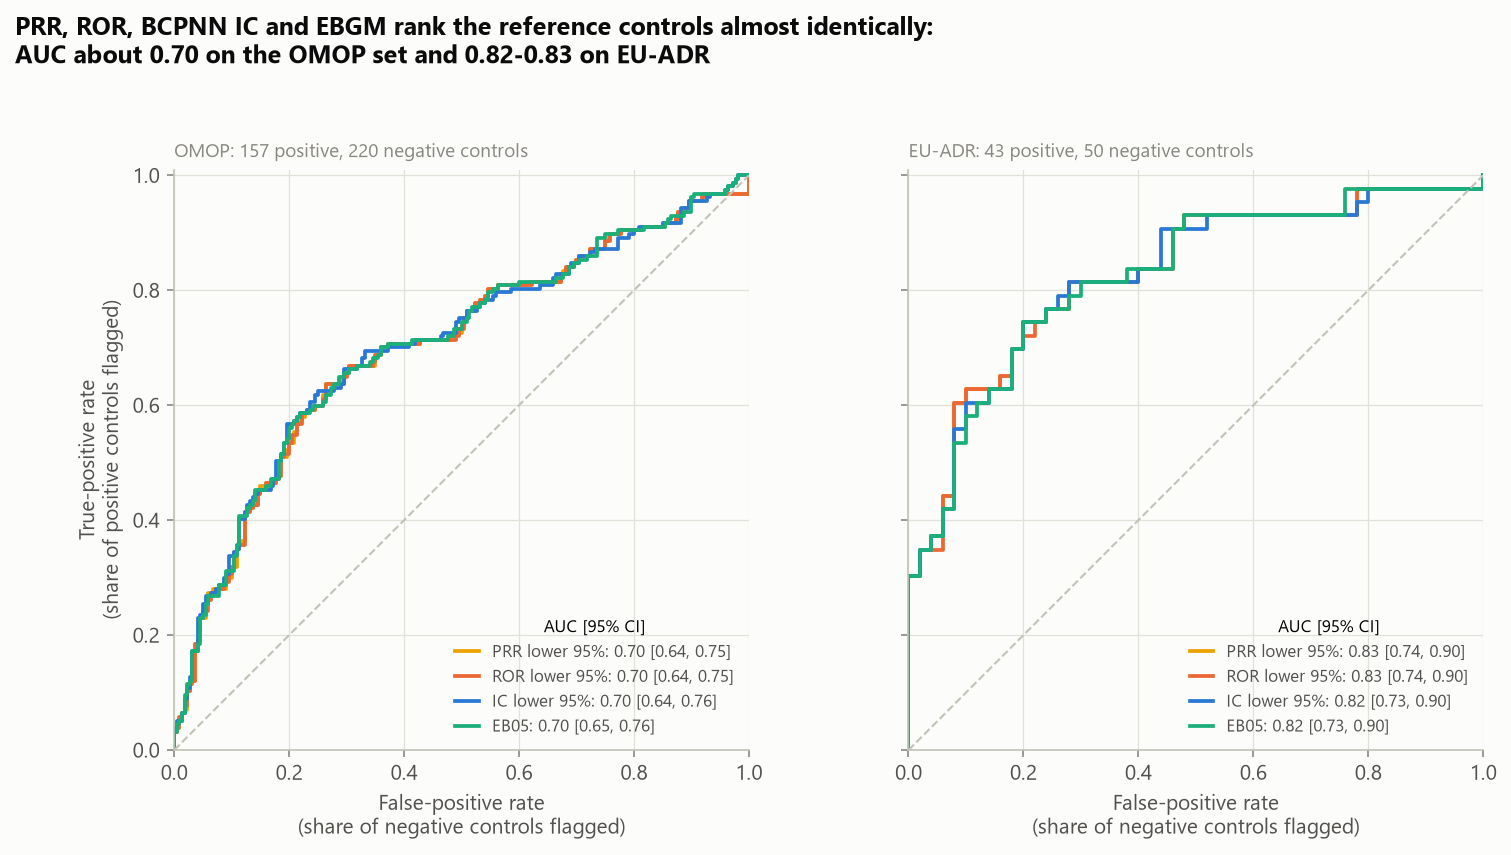

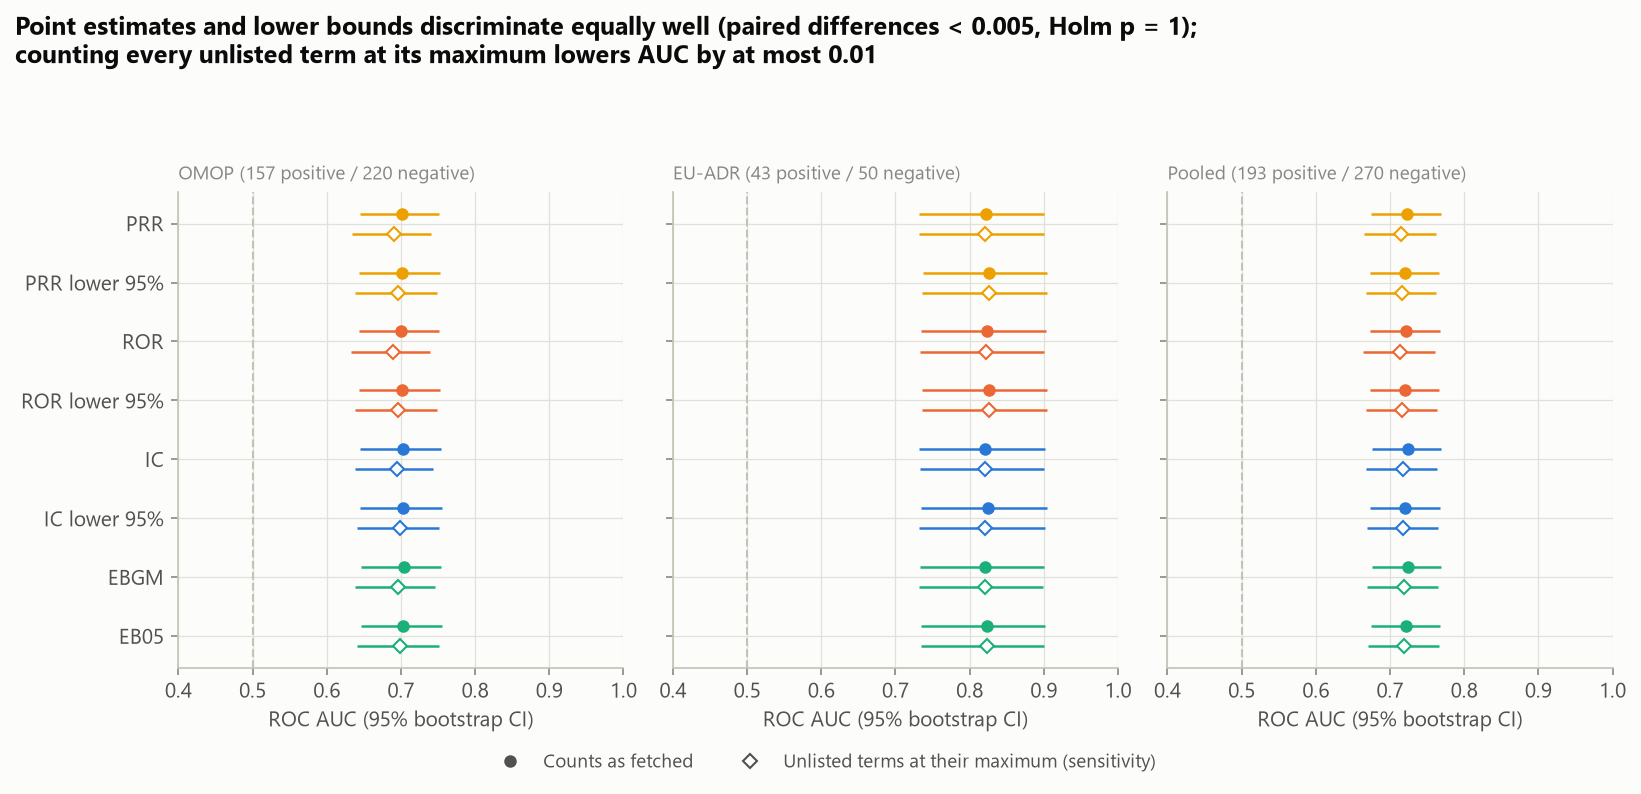

In [6]:
display(Image(FIG / '01_roc.png'))
display(Image(FIG / '02_auc.png'))

In [7]:
tests = pd.read_csv(RES / 'auc_tests.csv')
tests[tests.stratum == 'all reports'].round(4)

,score_1,score_2,auc_diff,ci_low,ci_high,p,p_holm,set,stratum
0,prr025,ror025,2.000e-04,-5.000e-04,9.000e-04,0.645,1.0,OMOP,all reports
1,prr025,ic025,-1.800e-03,-8.200e-03,4.400e-03,0.528,1.0,OMOP,all reports
2,prr025,eb05,-2.100e-03,-5.800e-03,1.100e-03,0.208,1.0,OMOP,all reports
3,ror025,ic025,-1.900e-03,-8.100e-03,4.000e-03,0.484,1.0,OMOP,all reports
4,ror025,eb05,-2.300e-03,-5.700e-03,7.000e-04,0.145,1.0,OMOP,all reports
5,ic025,eb05,-3.000e-04,-4.700e-03,4.000e-03,0.879,1.0,OMOP,all reports
6,prr,prr025,0.000e+00,-1.840e-02,1.840e-02,0.993,1.0,OMOP,all reports
7,ror,ror025,-1.000e-03,-1.970e-02,1.760e-02,0.901,1.0,OMOP,all reports
8,ic,ic025,2.000e-04,-2.020e-02,2.020e-02,0.985,1.0,OMOP,all reports
9,ebgm,eb05,8.000e-04,-1.480e-02,1.640e-02,0.947,1.0,OMOP,all reports


In [8]:
thr = pd.read_csv(RES / 'signal_thresholds.csv')
thr[thr.stratum == 'all reports'].round(3)

,rule,flagged,true_pos,false_pos,sensitivity,specificity,ppv,set,stratum
0,"PRR (Evans: PRR >= 2, chi2 >= 4, a >= 3)",147,93,54,0.592,0.755,0.633,OMOP,all reports
1,ROR lower 95% > 1 (a >= 3),217,112,105,0.713,0.523,0.516,OMOP,all reports
2,IC lower 95% > 0,209,112,97,0.713,0.559,0.536,OMOP,all reports
3,EB05 >= 2,115,75,40,0.478,0.818,0.652,OMOP,all reports
4,"PRR (Evans: PRR >= 2, chi2 >= 4, a >= 3)",43,30,13,0.698,0.740,0.698,EU-ADR,all reports
5,ROR lower 95% > 1 (a >= 3),65,40,25,0.930,0.500,0.615,EU-ADR,all reports
6,IC lower 95% > 0,63,39,24,0.907,0.520,0.619,EU-ADR,all reports
7,EB05 >= 2,39,30,9,0.698,0.820,0.769,EU-ADR,all reports
8,"PRR (Evans: PRR >= 2, chi2 >= 4, a >= 3)",184,117,67,0.606,0.752,0.636,Pooled,all reports
9,ROR lower 95% > 1 (a >= 3),275,145,130,0.751,0.519,0.527,Pooled,all reports


## Which outcomes are detectable?

Kidney injury and upper GI bleeding are the easiest OMOP outcomes, acute myocardial infarction the hardest, as
Harpaz et al. also found. The EU-ADR-only outcomes have 5 positive and 5 negative pairs each, too few to rank.

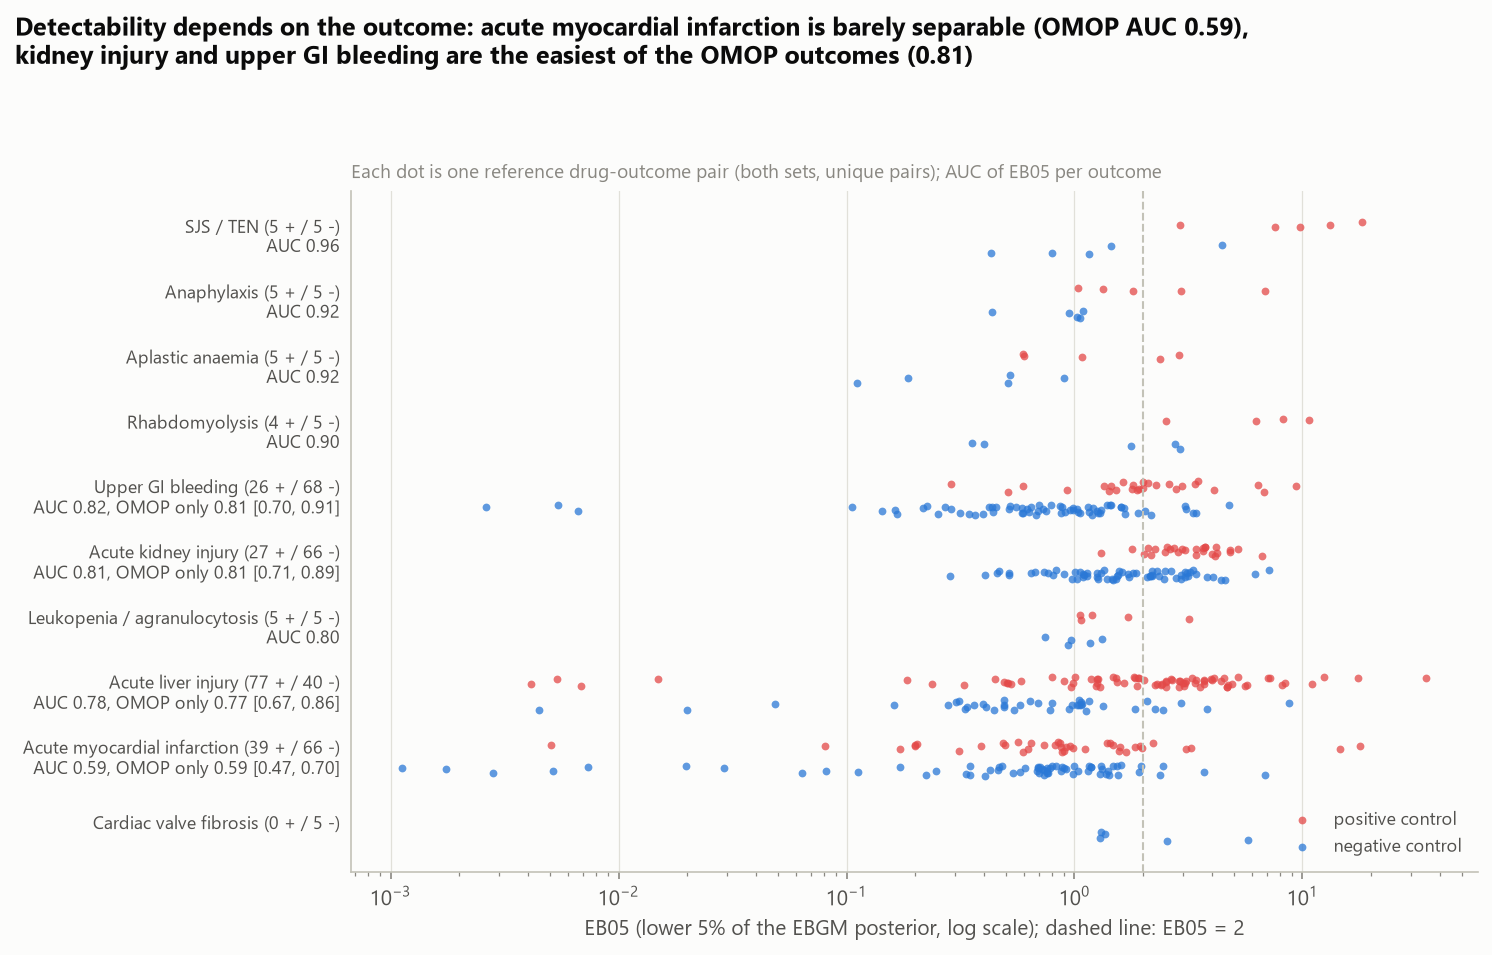

,score,auc,ci_low,ci_high,n_pos,n_neg,set,outcome
0,prr025,0.817,0.721,0.899,24,61,OMOP,acute_kidney_injury
1,ror025,0.816,0.721,0.899,24,61,OMOP,acute_kidney_injury
2,ic025,0.805,0.704,0.889,24,61,OMOP,acute_kidney_injury
3,eb05,0.809,0.710,0.891,24,61,OMOP,acute_kidney_injury
4,prr025,0.765,0.666,0.858,75,35,OMOP,acute_liver_injury
5,ror025,0.766,0.666,0.858,75,35,OMOP,acute_liver_injury
6,ic025,0.777,0.678,0.865,75,35,OMOP,acute_liver_injury
7,eb05,0.771,0.670,0.861,75,35,OMOP,acute_liver_injury
8,prr025,0.589,0.473,0.702,35,61,OMOP,acute_myocardial_infarction
9,ror025,0.588,0.472,0.700,35,61,OMOP,acute_myocardial_infarction


In [9]:
display(Image(FIG / '07_outcomes.png'))
pd.read_csv(RES / 'auc_by_outcome.csv').round(3)

## Where the methods go wrong

The highest-scoring negative controls are a catalogue of reporting biases: drugs whose indication is linked to the
outcome (sucralfate for duodenal ulcer with GI bleeding, gatifloxacin for pyelonephritis with kidney injury,
furosemide for heart failure with valve disease), drugs taken together with a drug that causes the outcome (HIV
regimens with tenofovir and kidney injury), and possible misclassifications in the reference set (oral sodium
phosphate and kidney injury). The lowest-scoring positive controls are mostly drugs with a few hundred reports in
the whole window, and myocardial infarction pairs.

In [10]:
ev = ref[ref.evaluable].drop_duplicates(['drug', 'outcome'])
print('highest-scoring negative controls (EB05):')
display(ev[ev.ground_truth == 0].nlargest(12, 'eb05')[['set', 'drug', 'outcome', 'indication', 'a', 'eb05']])
print('lowest-scoring positive controls (EB05):')
ev[ev.ground_truth == 1].nsmallest(12, 'eb05')[['set', 'drug', 'outcome', 'indication', 'a', 'n_drug', 'eb05']]

highest-scoring negative controls (EB05):


,set,drug,outcome,indication,a,eb05
22,omop,paromomycin,acute_liver_injury,Acute Intestinal Amebiasis,21,8.744
49,omop,darunavir,acute_kidney_injury,HIV Infection,2083,7.143
112,omop,ferrous gluconate,acute_myocardial_infarction,Iron Deficiency Anemia,253,6.861
59,omop,gatifloxacin,acute_kidney_injury,E. Coli Pyelonephritis,120,6.182
481,euadr,furosemide,cardiac_valve_fibrosis,Pulmonary Edema due to Chronic Heart Failure,1365,5.791
216,omop,sucralfate,upper_gi_bleeding,Duodenal Ulcer,642,4.758
40,omop,benzonatate,acute_kidney_injury,Cough,1369,4.566
452,euadr,ipratropium,sjs_ten,Chronic Obstructive Pulmonary Disease with Bronchospasms,369,4.431
73,omop,nelfinavir,acute_kidney_injury,HIV Infection,122,4.399
410,euadr,ferrous sulfate,acute_kidney_injury,Iron Deficiency Anemia,3306,4.054


lowest-scoring positive controls (EB05):


,set,drug,outcome,indication,a,n_drug,eb05
246,omop,enalaprilat,acute_liver_injury,Hypertension,0,240,0.004
333,omop,amoxapine,acute_myocardial_infarction,Depression,0,327,0.005
298,omop,tolcapone,acute_liver_injury,Idiopathic Parkinsonism,0,206,0.005
269,omop,moexipril,acute_liver_injury,Hypertension,0,177,0.007
253,omop,gemifloxacin,acute_liver_injury,Bacterial Pneumonia,0,101,0.015
425,euadr,levonorgestrel,acute_myocardial_infarction,Pregnancy Contraception,69,125006,0.081
344,omop,estropipate,acute_myocardial_infarction,Vasomotor Symptoms associated with Menopause,1,301,0.171
304,omop,zafirlukast,acute_liver_injury,Bronchial Asthma,4,1222,0.184
349,omop,frovatriptan,acute_myocardial_infarction,Migraine,3,1178,0.200
340,omop,enalaprilat,acute_myocardial_infarction,Hypertension,1,240,0.201


## Textbook signals and active comparators

The three signals named in the brief all stand out against every other report. Comparing each drug with drugs of the
same therapeutic area (an active-comparator analysis within FAERS) shows how much of the ratio is about the patients:
the fluoroquinolone tendon signal survives (ROR 26 for levofloxacin against other antibiotics), the isotretinoin
depression signal shrinks to 2.6 against other acne antibiotics, and ezetimibe turns out to be a poor comparator for
statins because it is mostly taken with one.

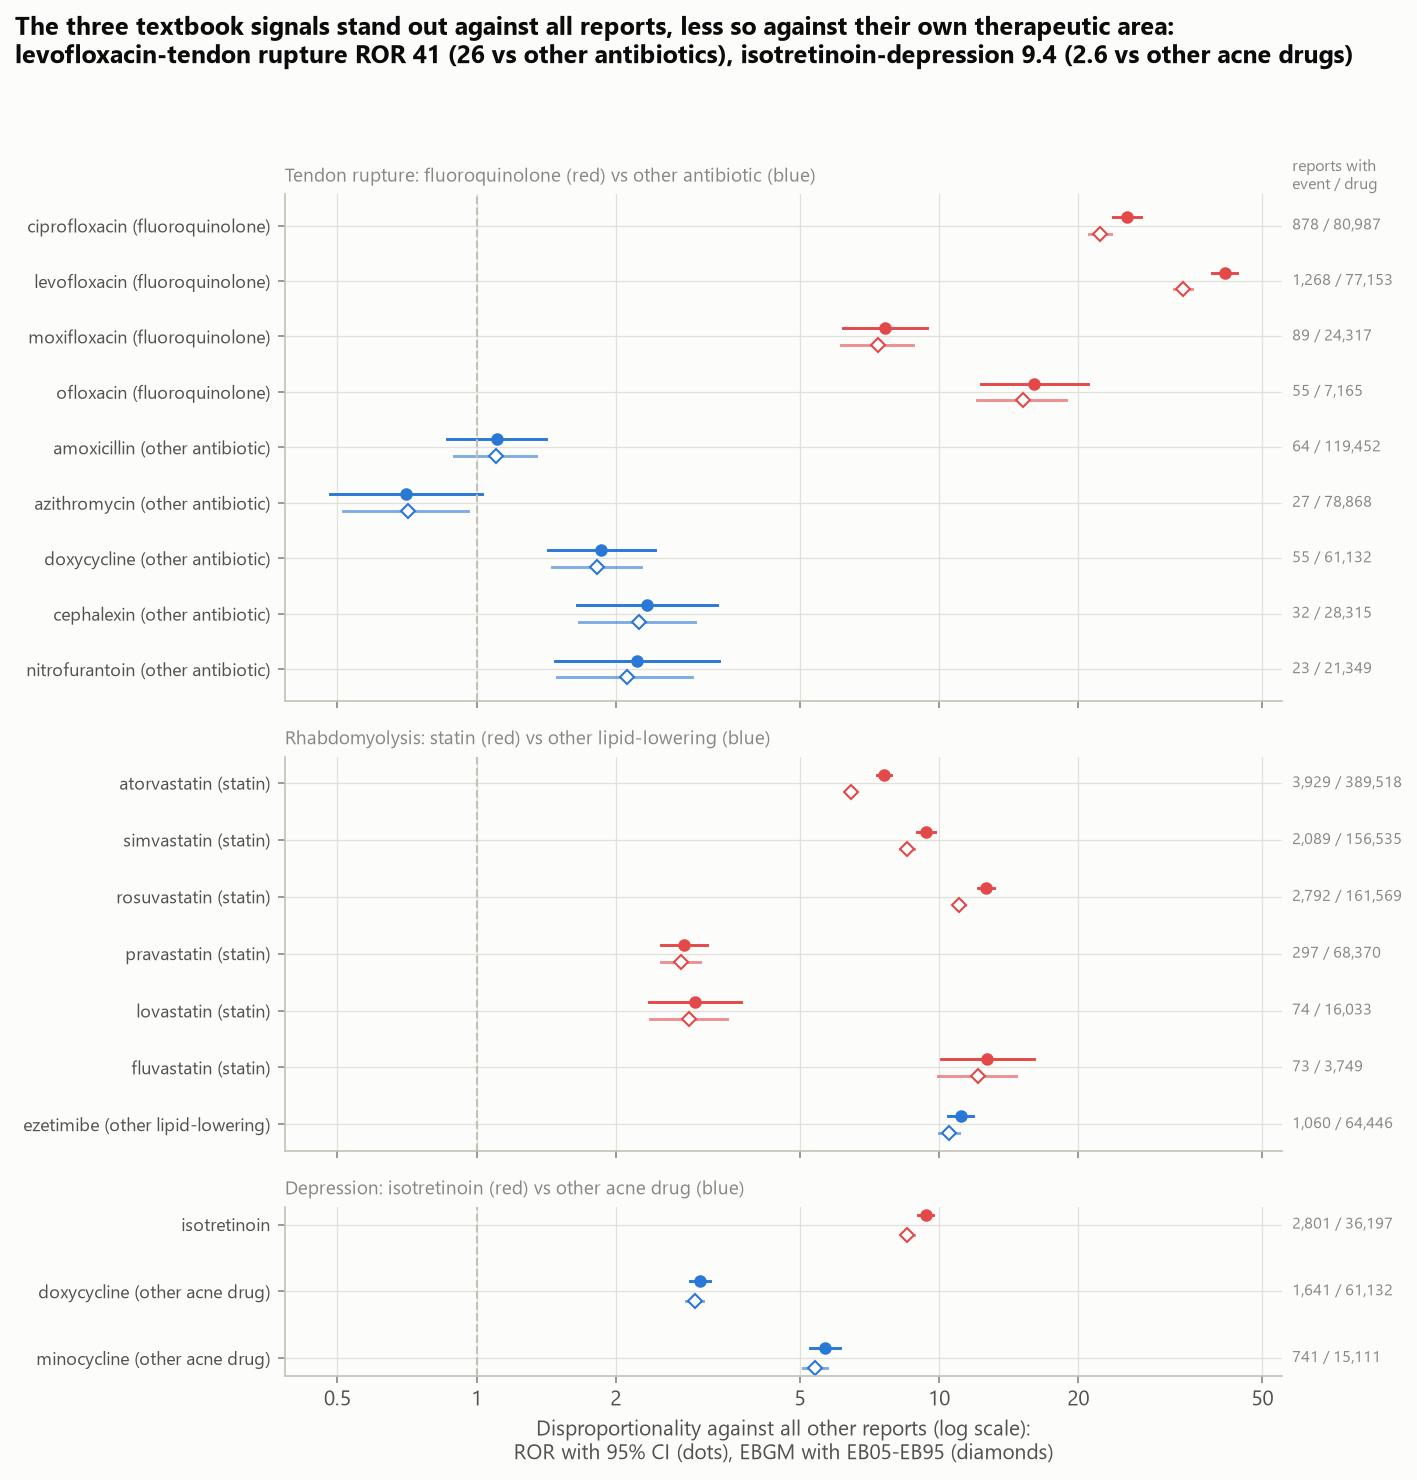

,event,drug,comparator,a,n_drug,comparator_a,comparator_reports,ror_vs_all,ror_vs_comparator,ci_low,ci_high
0,tendon_rupture,ciprofloxacin,"other antibiotic (amoxicillin, azithromycin, doxycycline, cephalexin, nitrof...",878,80987,201,309116,25.51,16.84,14.45,19.64
1,tendon_rupture,levofloxacin,"other antibiotic (amoxicillin, azithromycin, doxycycline, cephalexin, nitrof...",1268,77153,201,309116,41.43,25.68,22.13,29.81
2,tendon_rupture,moxifloxacin,"other antibiotic (amoxicillin, azithromycin, doxycycline, cephalexin, nitrof...",89,24317,201,309116,7.64,5.65,4.40,7.25
3,tendon_rupture,ofloxacin,"other antibiotic (amoxicillin, azithromycin, doxycycline, cephalexin, nitrof...",55,7165,201,309116,16.04,11.89,8.81,16.04
4,rhabdomyolysis,atorvastatin,other lipid-lowering (ezetimibe),3929,389518,1060,64446,7.61,0.61,0.57,0.65
5,rhabdomyolysis,simvastatin,other lipid-lowering (ezetimibe),2089,156535,1060,64446,9.38,0.81,0.75,0.87
6,rhabdomyolysis,rosuvastatin,other lipid-lowering (ezetimibe),2792,161569,1060,64446,12.60,1.05,0.98,1.13
7,rhabdomyolysis,pravastatin,other lipid-lowering (ezetimibe),297,68370,1060,64446,2.81,0.26,0.23,0.30
8,rhabdomyolysis,lovastatin,other lipid-lowering (ezetimibe),74,16033,1060,64446,2.97,0.28,0.22,0.35
9,rhabdomyolysis,fluvastatin,other lipid-lowering (ezetimibe),73,3749,1060,64446,12.71,1.19,0.93,1.51


In [11]:
display(Image(FIG / '03_textbook_signals.png'))
pd.read_csv(RES / 'textbook_vs_comparators.csv').round(2)

## Shrinkage and an unsupervised screen

EBGM differs from the observed-to-expected ratio only for pairs with a handful of co-reports, which are rare in a
database of 15 million reports. The screen of three drugs' full reaction profiles shows what a reviewer would face:
the labelled reactions rank near the top (tendon rupture 2nd for levofloxacin, rhabdomyolysis 3rd for atorvastatin),
next to terms driven by litigation or co-prescribed drugs (type 2 diabetes and chronic kidney disease for
atorvastatin) and by risk-management programmes (exposure during pregnancy for isotretinoin).

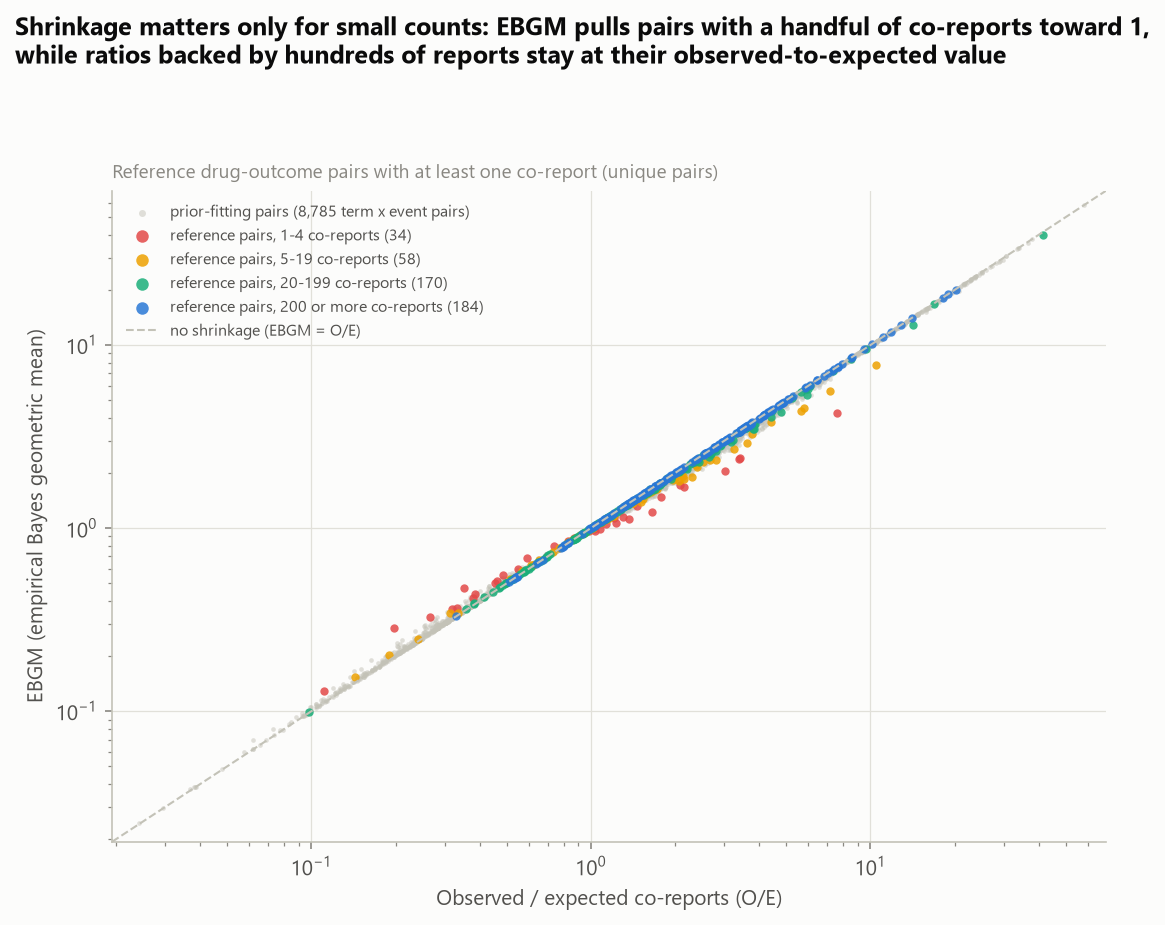

GPS prior: {'a1': 1.465283495731428, 'b1': 1.0442638720794784, 'a2': 0.43764307460493607, 'b2': 0.14730126915106262, 'w': 0.7469861919786285, 'loglik': -53855.19702033919, 'n_pairs': 8785}


,drug,pt,a,n_event,prr,ic025,ebgm,eb05
0,atorvastatin,TYPE 2 DIABETES MELLITUS,5894,19316,16.503,3.519,11.769,11.519
1,atorvastatin,MIXED LIVER INJURY,446,2349,8.808,2.726,7.293,6.740
2,atorvastatin,RHABDOMYOLYSIS,3913,23509,7.504,2.636,6.418,6.251
3,atorvastatin,HEPATITIS CHOLESTATIC,527,3489,6.687,2.410,5.801,5.396
4,atorvastatin,HYPOMAGNESAEMIA,1413,9711,6.400,2.410,5.604,5.363
5,atorvastatin,CORONARY ARTERY DISEASE,1330,9157,6.386,2.405,5.593,5.345
6,atorvastatin,END STAGE RENAL DISEASE,2509,17910,6.123,2.376,5.400,5.224
7,atorvastatin,CHOLESTATIC LIVER INJURY,253,1695,6.594,2.329,5.704,5.134
8,atorvastatin,MACULAR DEGENERATION,1106,8066,5.972,2.314,5.278,5.022
9,atorvastatin,CORONARY ARTERY OCCLUSION,860,6351,5.886,2.284,5.209,4.923


In [12]:
display(Image(FIG / '04_shrinkage.png'))
print('GPS prior:', meta['gps_prior'])
scr = pd.read_csv(RES / 'screening_pts.csv')
scr[scr.rank_eb05 <= 10][['drug', 'pt', 'a', 'n_event', 'prr', 'ic025', 'ebgm', 'eb05']]

## Stimulated reporting and new drugs

Ranitidine's reports rose 18-fold after the 2019 NDMA alert, and 41% of them were sent by lawyers (2.8% of all
reports). The screen's suspicious pairs show the same pattern (`reporter_mix_checks.csv`, chosen after reading the
screen). A burst of consumer reports in early 2017 lifted the levofloxacin-aortic aneurysm PRR from about 10 to 448
for one year. For new drugs, only erenumab shows an early peak and decline; dupilumab and tirzepatide reports keep
growing with uptake, and without prescription volumes the two cannot be separated.

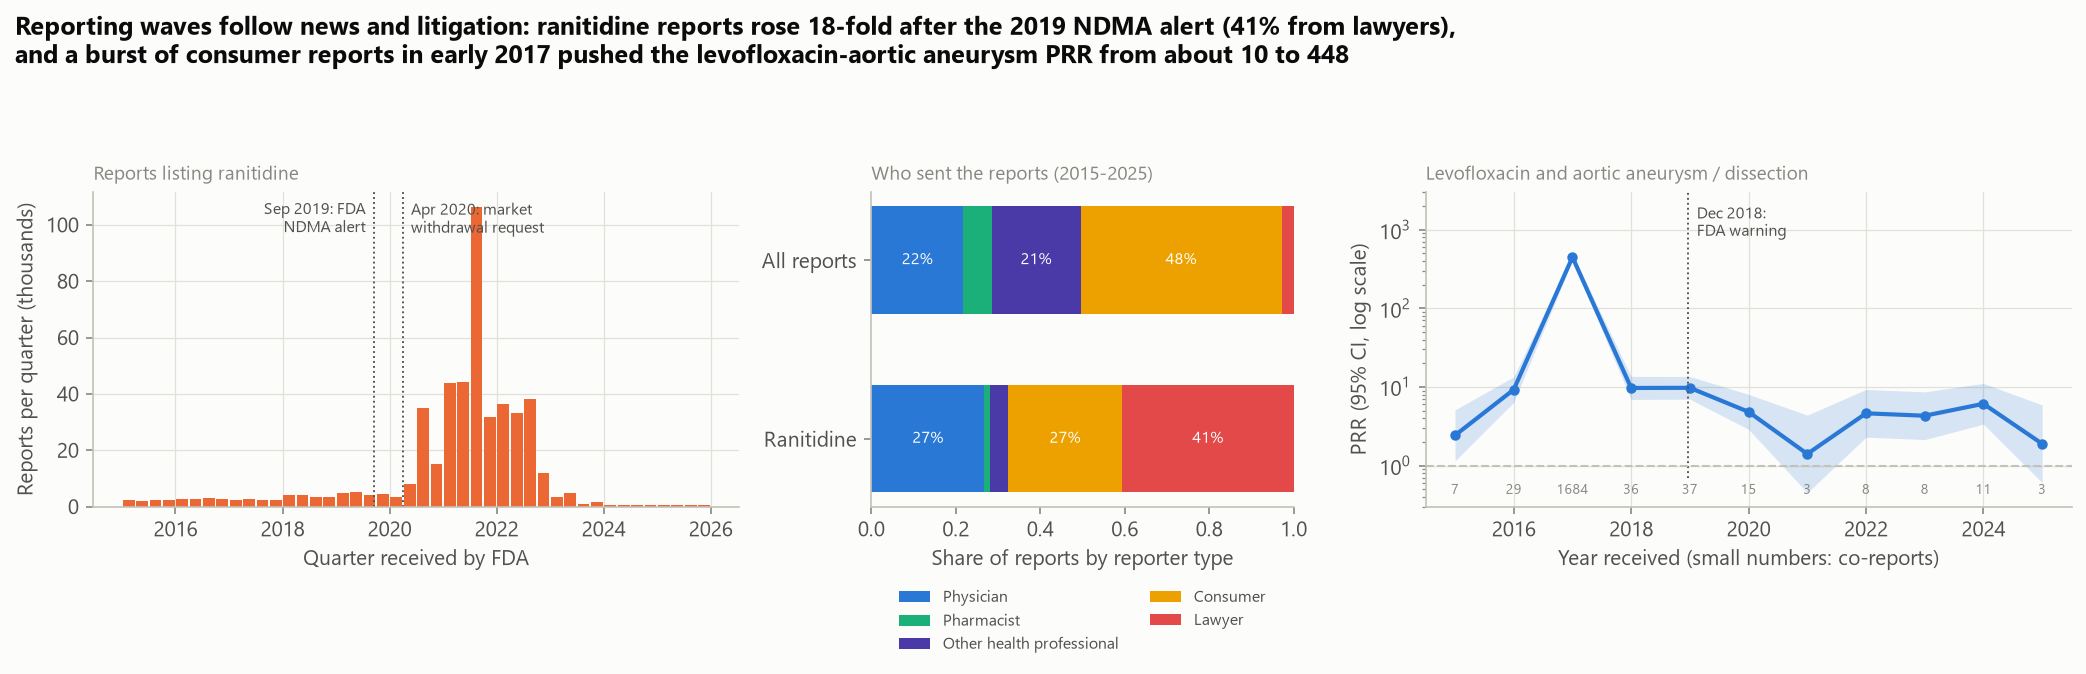

,reporter,all_reports,ranitidine_reports,all_share,ranitidine_share
0,Physician,3213163,128296,0.218,0.268
1,Pharmacist,990933,6033,0.067,0.013
2,Other health professional,3099040,20723,0.210,0.043
3,Lawyer,415988,194418,0.028,0.406
4,Consumer,7021798,129441,0.476,0.270


In [13]:
display(Image(FIG / '05_stimulated_reporting.png'))
mix = pd.read_csv(RES / 'reporter_mix.csv')
mix.assign(all_share=mix.all_reports / mix.all_reports.sum(),
           ranitidine_share=mix.ranitidine_reports / mix.ranitidine_reports.sum()).round(3)

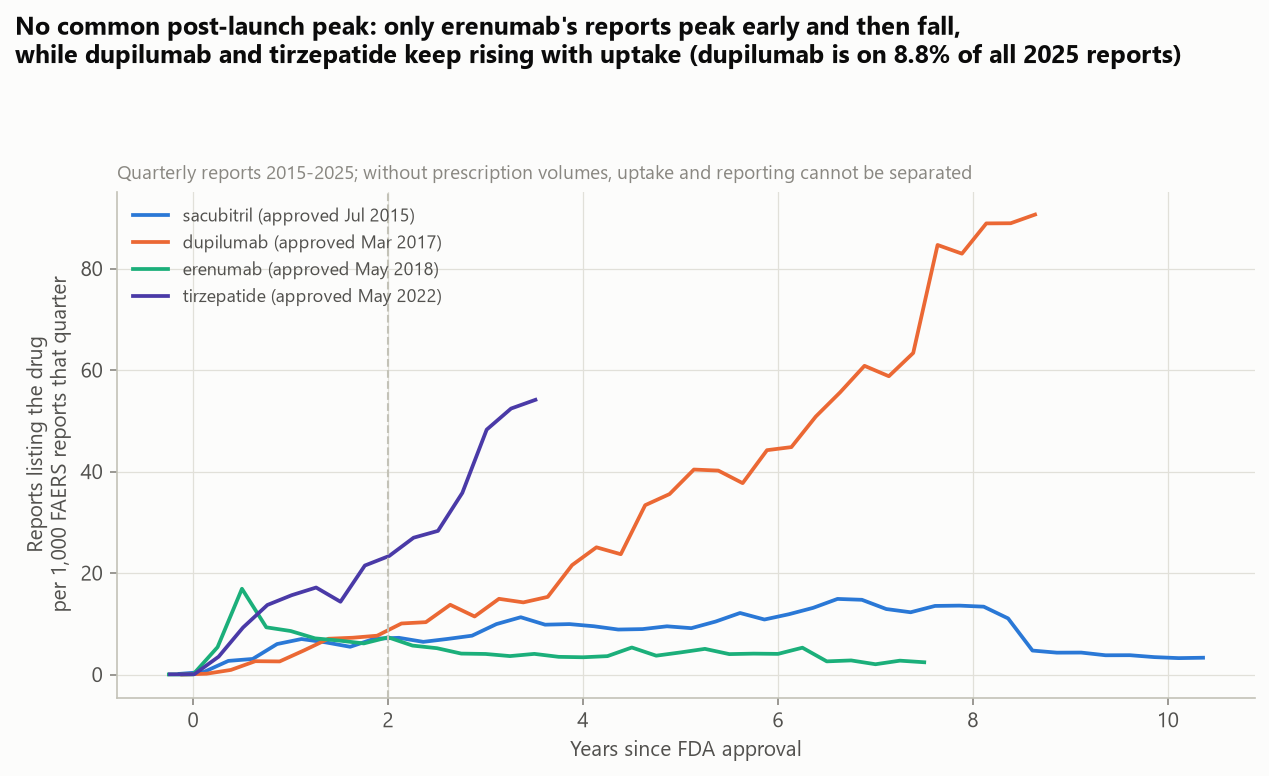

In [14]:
display(Image(FIG / '06_new_drugs.png'))

## Takeaways

- The choice between PRR, ROR, IC and EBGM changes almost nothing in how pairs are ranked; the threshold decides how
  many pairs are flagged, and the data (reference set, outcome, report volume) decides how well any method does.
- Counting is the hard part with openFDA: reports not patients, unmerged duplicates, any-role drugs, multi-term
  drugs and outcomes, and the 999-term cap all need handling, and each is a source of error.
- Every high score needs a look at who reported it, when, and with which other drugs before it becomes a signal; a
  comparator from the same therapeutic area is a cheap first check against confounding by indication.